#Partie 1 — Explorer et vérifier les données

**1. Chargement et exploration des données**

In [62]:
import pandas as pd
df = pd.read_csv("transactions_TP2.csv")
print(df.head())
print(df.shape)
print(df.dtypes)

  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat           non    aucune_fraude   

   fraude  
0       0  
1       0  
2       0  
3       0  
4 

**2. Analyse des valeurs manquantes**

In [63]:
print(df.isna().sum())
print(df.isna().mean())

id_operation          0
id_client             0
montant_dh          110
anciennete_mois     137
nb_ops_24h           53
heure                 0
canal               159
appareil            122
region              103
international         0
resultat_enquete      0
fraude                0
dtype: int64
id_operation        0.000000
id_client           0.000000
montant_dh          0.036125
anciennete_mois     0.044992
nb_ops_24h          0.017406
heure               0.000000
canal               0.052217
appareil            0.040066
region              0.033826
international       0.000000
resultat_enquete    0.000000
fraude              0.000000
dtype: float64


In [64]:
tableau = pd.DataFrame({
    'Nombres Manquants' : df.isna().sum(),
    'Pourcentage' : df.isna().mean()*100
})
tableau = tableau.sort_values(
    by='Pourcentage',
    ascending=False
)
print(tableau)

                  Nombres Manquants  Pourcentage
canal                           159     5.221675
anciennete_mois                 137     4.499179
appareil                        122     4.006568
montant_dh                      110     3.612479
region                          103     3.382594
nb_ops_24h                       53     1.740558
id_operation                      0     0.000000
id_client                         0     0.000000
heure                             0     0.000000
international                     0     0.000000
resultat_enquete                  0     0.000000
fraude                            0     0.000000


**3. Détection et suppression des doublons**

In [65]:
# Rechercher les opérations répétées
print(df.duplicated(subset="id_operation"))
print(df.duplicated(subset="id_operation").sum())
# Supprimer les doublons
df = df.drop_duplicates(subset="id_operation")
# Nombre de lignes restantes
len(df)

0       False
1       False
2       False
3       False
4       False
        ...  
3040    False
3041    False
3042    False
3043    False
3044    False
Length: 3045, dtype: bool
45


3000

**4. Analyse des montants**

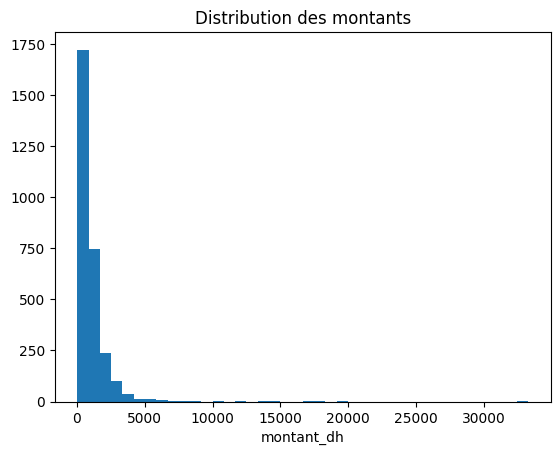

In [66]:
import matplotlib.pyplot as plt
plt.hist(df["montant_dh"], bins=40)
plt.xlabel("montant_dh")
plt.ylabel("")
plt.title("Distribution des montants")
plt.show()

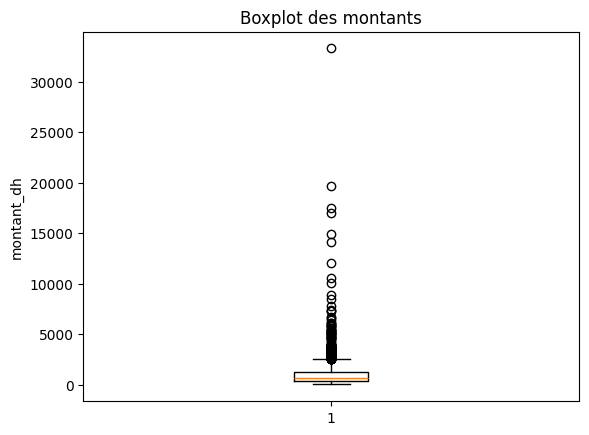

In [67]:
plt.boxplot(df["montant_dh"].dropna())
plt.title("Boxplot des montants")
plt.ylabel("montant_dh")
plt.show()

In [68]:
df["montant_dh"].nlargest(10)

,montant_dh
2660,33281.23
539,19658.42
1775,17496.64
1557,16962.99
2556,14951.95
65,14135.85
1010,12046.21
32,10598.93
1313,10028.37
2145,8910.60


**5. Analyse de la variable cible**

In [69]:
print(df["fraude"].value_counts(normalize=True)*100)

fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


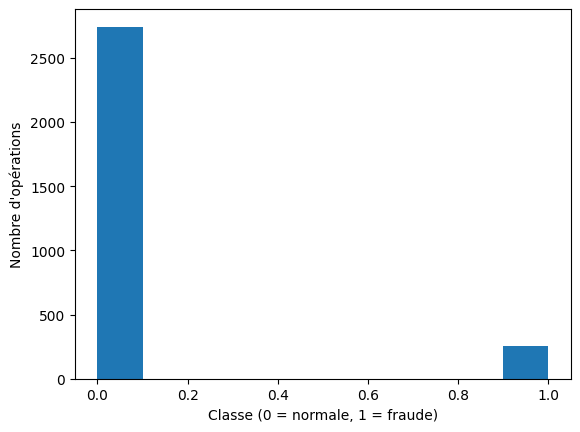

In [70]:
plt.hist(df["fraude"])
plt.xlabel("Classe (0 = normale, 1 = fraude)")
plt.ylabel("Nombre d'opérations")
plt.show()

#Partie 2 — Préparer les données sans fuite

**7. Créez X (variables à préparer) et y (fraude)**

In [71]:
X = df.drop(columns=["id_operation", "id_client", "resultat_enquete", "fraude"])
y = df["fraude"]

**8. Séparation train / test**

In [72]:
from sklearn.model_selection import train_test_split
X_train ,X_test, y_train, y_test = train_test_split(
     X, y,
     test_size=0.20,
     stratify=y,
     random_state=42
)

In [73]:
#Comparez les proportions de fraude
print("Groupe de référence: ")
print(y_train.value_counts(normalize=True)*100)

print("Groupe de vérification: ")
print(y_test.value_counts(normalize=True)*100)

Groupe de référence: 
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64
Groupe de vérification: 
fraude
0    91.333333
1     8.666667
Name: proportion, dtype: float64


**9. Identification des variables**

In [74]:
numeriques = [
    "montant_dh",
    "anciennete_mois",
    "nb_ops_24h",
    "heure"
]
categorielle = [
    "canal",
    "appareil",
    "region",
    "international"
]

**10. Prétraitement des variables numériques**

In [75]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_num = num_pipe.fit_transform(X_train[numeriques])
X_test_num = num_pipe.transform(X_test[numeriques])


**11. Prétraitement des variables catégorielles**

In [76]:
from sklearn.preprocessing import OneHotEncoder
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

X_train_cat = cat_pipe.fit_transform(X_train[categorielle])
X_test_cat = cat_pipe.transform(X_test[categorielle])

**12. Combinaison des pipelines**

In [77]:
from sklearn.compose import ColumnTransformer
prep = ColumnTransformer([
    ("num", num_pipe, numeriques),
    ("cat", cat_pipe, categorielle)
])

X_train_prep = prep.fit_transform(X_train)
X_test_prep = prep.transform(X_test)

In [78]:
print("Groupe de référence :", X_train_prep.shape)
print("Groupe de vérification :", X_test_prep.shape)

Groupe de référence : (2400, 18)
Groupe de vérification : (600, 18)


**13. Comparaison entre StandardScaler et RobustScaler**

In [79]:
from sklearn.preprocessing import RobustScaler

standard = StandardScaler()
robust = RobustScaler()

standard.fit(X_train[["montant_dh"]])
robust.fit(X_train[["montant_dh"]])

montant_normal = X_train["montant_dh"].median()
montant_extreme = X_train["montant_dh"].max()

exemple = pd.DataFrame({
    "montant_dh": [montant_normal, montant_extreme]
})

print("Montants originaux :", exemple)

print("StandardScaler :")
print(standard.transform(exemple))

print("RobustScaler :")
print(robust.transform(exemple))

Montants originaux :    montant_dh
0      710.79
1    33281.23
StandardScaler :
[[-0.23805897]
 [23.86583016]]
RobustScaler :
[[ 0.        ]
 [38.01482873]]


#Partie 3 — Comparer les méthodes de mise à l’échelle

**15. Calcul des quartiles et de l'IQR**

In [80]:
Q1 = X_train["montant_dh"].quantile(0.25)
Q3 = X_train["montant_dh"].quantile(0.75)
IQR = Q3 - Q1
print("Q1 = ", Q1)
print("Q3 = ", Q3)
print("IQR = ", IQR)

Q1 =  393.095
Q3 =  1249.8775
IQR =  856.7825


**16. Détection des valeurs extrêmes**

In [81]:
Q1 = X_train["montant_dh"].quantile(0.25)
Q3 = X_train["montant_dh"].quantile(0.75)
IQR = Q3 - Q1

Inf = Q1 - 1.5 * IQR
Sup = Q3 + 1.5 * IQR

outliers = X_train[
    (X_train["montant_dh"] < Inf) |
    (X_train["montant_dh"] > Sup)
]

print("Borne Inferieur :", Inf)
print("Borne Supérieur:", Sup)
print("Nombre de lignes :", len(outliers))

print(outliers["montant_dh"].head(10))

Borne Inferieur : -892.0787499999999
Borne Supérieur: 2535.05125
Nombre de lignes : 146
1601     2940.62
1348     3449.17
2660    33281.23
1489     3988.17
2049     3942.99
2088     2645.74
1105     6733.98
1074     2535.89
396      3002.07
329      5021.72
Name: montant_dh, dtype: float64


**17. Conservation ou limitation des valeurs extrêmes**

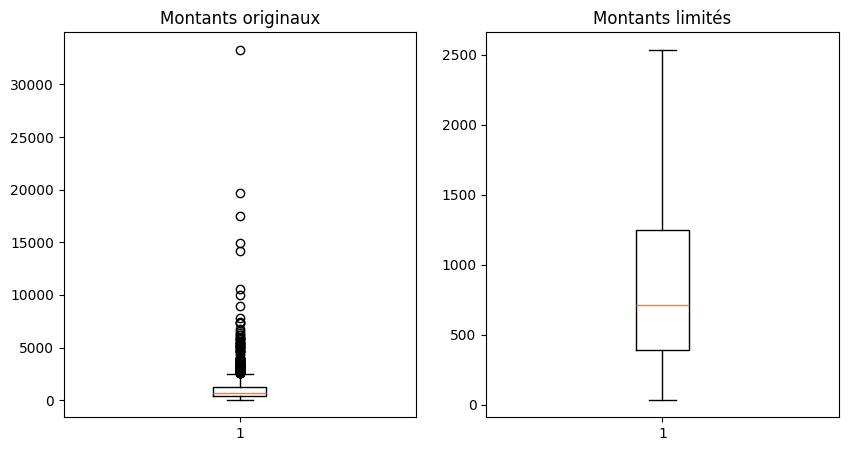

In [82]:
montants_originaux = X_train["montant_dh"].dropna()

montants_limites = X_train["montant_dh"].clip(
    lower=Inf,
    upper=Sup
).dropna()

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.boxplot(montants_originaux)
plt.title("Montants originaux")

plt.subplot(1, 2, 2)
plt.boxplot(montants_limites)
plt.title("Montants limités")

plt.show()

**18. Application des trois méthodes de mise à l'échelle**

In [83]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

minmax = MinMaxScaler()
standard = StandardScaler()
robust = RobustScaler()

# Ajustement sur le groupe de référence
minmax.fit(X_train[["montant_dh"]])
standard.fit(X_train[["montant_dh"]])
robust.fit(X_train[["montant_dh"]])

# Transformation du groupe de vérification
montant_minmax = minmax.transform(X_test[["montant_dh"]])
montant_standard = standard.transform(X_test[["montant_dh"]])
montant_robust = robust.transform(X_test[["montant_dh"]])

**19. Comparaison des montants transformés**

In [84]:
exemple = X_train["montant_dh"].dropna().sort_values()

valeurs = [
    exemple.iloc[int(len(exemple) * 0.25)],
    exemple.iloc[int(len(exemple) * 0.40)],
    exemple.iloc[int(len(exemple) * 0.60)],
    exemple.max()
]

comparaison = pd.DataFrame({
    "Montant original": valeurs,
    "MinMaxScaler": minmax.transform(pd.DataFrame({"montant_dh": valeurs})).flatten(),
    "StandardScaler": standard.transform(pd.DataFrame({"montant_dh": valeurs})).flatten(),
    "RobustScaler": robust.transform(pd.DataFrame({"montant_dh": valeurs})).flatten()
})

print(comparaison.round(3))

   Montant original  MinMaxScaler  StandardScaler  RobustScaler
0            393.10         0.011          -0.473        -0.371
1            569.84         0.016          -0.342        -0.165
2            881.78         0.025          -0.112         0.200
3          33281.23         1.000          23.866        38.015


**20. Comparaison des histogrammes**

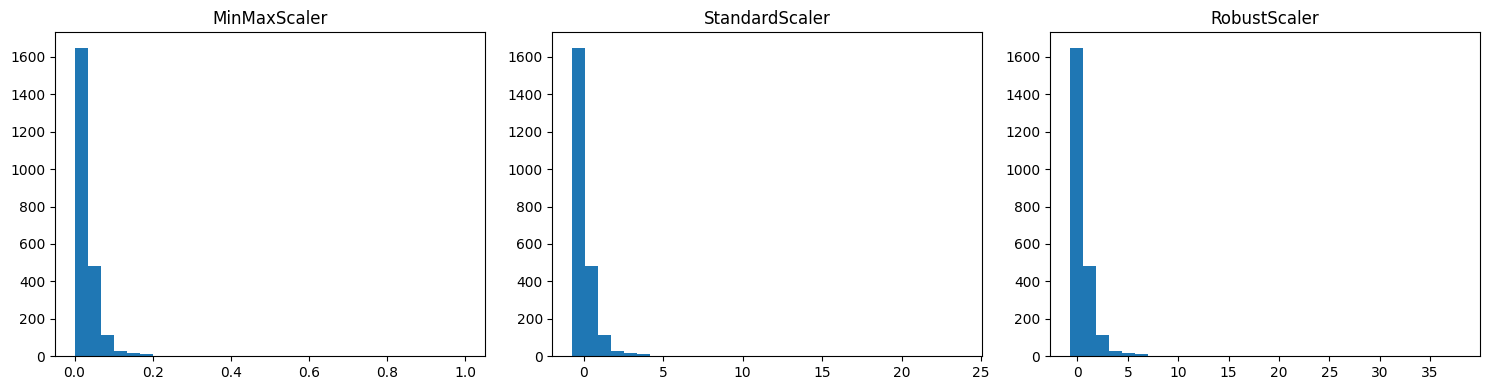

In [85]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(X_train["montant_dh"].dropna().pipe(
    lambda x: minmax.transform(x.to_frame())
).flatten(), bins=30)
plt.title("MinMaxScaler")

plt.subplot(1, 3, 2)
plt.hist(X_train["montant_dh"].dropna().pipe(
    lambda x: standard.transform(x.to_frame())
).flatten(), bins=30)
plt.title("StandardScaler")

plt.subplot(1, 3, 3)
plt.hist(X_train["montant_dh"].dropna().pipe(
    lambda x: robust.transform(x.to_frame())
).flatten(), bins=30)
plt.title("RobustScaler")

plt.tight_layout()
plt.show()

**21. Dépassement de la valeur 1 avec MinMaxScaler**

In [86]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

reference = [[100], [200], [300]]
scaler.fit(reference)

nouvelle_transaction = [[400]]

print(scaler.transform(nouvelle_transaction))

[[1.5]]


#Partie 4 — Préparer des classes déséquilibrées

**22. Analyse du déséquilibre des classes**

In [87]:
print(y_train.value_counts())

fraude
0    2194
1     206
Name: count, dtype: int64


In [88]:
nb_normal = (y_train == 0).sum()
nb_fraude = (y_train == 1).sum()

rapport = nb_normal / nb_fraude

print("Nombre de transactions normales :", nb_normal)
print("Nombre de fraudes :", nb_fraude)
print("Rapport normal / fraude :", rapport)

Nombre de transactions normales : 2194
Nombre de fraudes : 206
Rapport normal / fraude : 10.650485436893204


**23. RandomOverSampler**

In [89]:
from imblearn.over_sampling import RandomOverSampler
print("Avant :")
print(y_train.value_counts())

ros = RandomOverSampler(random_state=42)

X_over, y_over = ros.fit_resample(X_train, y_train)

print("Après :")
print(y_over.value_counts())

Avant :
fraude
0    2194
1     206
Name: count, dtype: int64
Après :
fraude
0    2194
1    2194
Name: count, dtype: int64


**24. RandomUnderSampler**

In [90]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)

X_under, y_under = rus.fit_resample(X_train, y_train)

print("Avant :")
print(y_train.value_counts())

print("\nAprès :")
print(y_under.value_counts())

Avant :
fraude
0    2194
1     206
Name: count, dtype: int64

Après :
fraude
0    206
1    206
Name: count, dtype: int64


In [91]:
print("Lignes initiales :", len(y_train))
print("Lignes conservées :", len(y_under))
print("Lignes supprimées :", len(y_train) - len(y_under))

Lignes initiales : 2400
Lignes conservées : 412
Lignes supprimées : 1988


**25. Illustration de SMOTE**

In [92]:
import numpy as np

A = np.array([10, 20])
B = np.array([20, 40])

alpha = 0.5

nouvelle_observation = A + alpha * (B - A)

print("Observation A :", A)
print("Observation B :", B)
print("Nouvelle observation :", nouvelle_observation)

Observation A : [10 20]
Observation B : [20 40]
Nouvelle observation : [15. 30.]


**27. Comparaison des effectifs**

In [93]:
tableau = pd.DataFrame({
    "Avant rééquilibrage": y_train.value_counts(),
    "Après suréchantillonnage": y_over.value_counts(),
    "Après sous-échantillonnage": y_under.value_counts()
})

print(tableau)

        Avant rééquilibrage  Après suréchantillonnage  \
fraude                                                  
0                      2194                      2194   
1                       206                      2194   

        Après sous-échantillonnage  
fraude                              
0                              206  
1                              206  


#Partie 5 — Vérification et enregistrement des données préparées

**28. Création du transformateur final**

In [94]:
numeriques = ["montant_dh", "anciennete_mois", "nb_ops_24h", "heure"]
categorielle = ["canal", "appareil", "region", "international"]

num_pipe_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

cat_pipe_final = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

**29. Ajustement et transformation**

In [95]:
prep_final = ColumnTransformer([
    ("num", num_pipe_final, numeriques),
    ("cat", cat_pipe_final, categorielle)
])

In [96]:
X_train_final = prep_final.fit_transform(X_train)
X_test_final = prep_final.transform(X_test)

print("Dimensions train :", X_train_final.shape)
print("Dimensions test :", X_test_final.shape)

print("Valeurs manquantes train :", np.isnan(X_train_final).sum())
print("Valeurs manquantes test :", np.isnan(X_test_final).sum())

Dimensions train : (2400, 18)
Dimensions test : (600, 18)
Valeurs manquantes train : 0
Valeurs manquantes test : 0


**30. Gestion des catégories inconnues**

In [97]:
nouvelle_ligne = X_train.iloc[[0]].copy()
nouvelle_ligne["canal"] = "NOUVEAU_CANAL"
resultat = prep_final.transform(nouvelle_ligne)
print(resultat)

[[-0.35673954 -0.4047619   0.          0.38461538  0.          0.
   0.          0.          1.          0.          0.          0.
   0.          1.          0.          0.          0.          1.        ]]


**31. Enregistrement du transformateur**

In [98]:
import joblib

joblib.dump(prep_final, "pretraitement_final.pkl")
prep_recharge = joblib.load("pretraitement_final.pkl")

echantillon = X_train.iloc[:5]
resultat1 = prep_final.transform(echantillon)
resultat2 = prep_recharge.transform(echantillon)
print(np.allclose(resultat1, resultat2))

True
